# Signal Processing

Sygnałem może być dowolna wielkość zmieniająca się w czasie (sygnał czasowy, np. dźwięk lub temperatura) albo w przestrzeni (sygnał przestrzenny, np. obraz 2D). Choć w rzeczywistości większość sygnałów ma charakter ciągły, w obliczeniach komputerowych operujemy na sygnałach dyskretnych, powstałych przez próbkowanie sygnału ciągłego w równych odstępach czasu.

In [106]:
from scipy import fftpack  # algorytmy szybkiej transformacji Fouriera
from scipy import (
    signal,
)  # przetwarzania sygnałów: funkcje okien, sploty oraz projektowanie i aplikowanie filtrów cyfrowych (FIR, IIR)
import scipy.io.wavfile
from scipy import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

## 1. Spectral Analysis i Transformacja Fouriera

### Generowanie zaszumionego sygnału w dziedzinie czasu
Tworzymy funkcję `signal_samples(t)`, która symuluje pomiar sygnału złożonego z dwóch czystych fal sinusoidalnych o znanych częstotliwościach i amplitudach:
* składowej o częstotliwości $1\text{ Hz}$ i amplitudzie $2$,
* składowej o częstotliwości $22\text{ Hz}$ i amplitudzie $3$,
* oraz nałożonego na nie szumu losowego o rozkładzie normalnym (gaussowskim) ze średnią $0$ i odchyleniem standardowym $2$ (`2 * np.random.randn(...)`).

*Po co?* 
W praktyce pomiary fizyczne niemal nigdy nie są idealnie czyste. Chcemy sprawdzić, jak za pomocą transformacji Fouriera wydobyć ukryte składowe harmoniczne z sygnału, który na pierwszy rzut oka wygląda jak chaotyczny szum.

In [107]:
def signal_samples(t):
    return (
        2 * np.sin(2 * np.pi * t)
        + 3 * np.sin(22 * 2 * np.pi * t)
        + 2 * np.random.randn(*np.shape(t))
    )

### Dobór parametrów próbkowania
Aby móc badać sygnał ciągły metodami cyfrowymi, musimy zamienić go na ciąg próbek. Kluczową rolę odgrywa tu twierdzenie o próbkowaniu (Nyquista-Shannona): sygnał ciągły o paśmie ograniczonym do maksymalnej częstotliwości $B$ można wiernie odtworzyć z próbek dyskretnych, jeśli częstotliwość próbkowania $f_s$ spełnia warunek:
$$f_s \ge 2B$$
Wartość $f_s / 2 = B$ nazywamy częstotliwością Nyquista.

W kodzie poniżej:
1. Zakładamy, że chcemy badać widmo częstotliwości aż do $B = 30\text{ Hz}$.
2. Zgodnie z twierdzeniem Nyquista ustalamy częstotliwość próbkowania na $f_s = 2B = 60\text{ Hz}$.
3. Określamy pożądaną rozdzielczość częstotliwościową $\Delta f = 0.01\text{ Hz}$ (odstęp między kolejnymi prążkami).
4. Wyliczamy minimalną liczbę próbek $N = f_s / \Delta f = 6000$, jaka jest potrzebna do uzyskania takiej rozdzielczości.

In [108]:
B = 30.0
f_s = 2 * B
delta_f = 0.01
N = int(f_s / delta_f)

### Całkowity czas pomiaru (okres próbkowania)
Rozdzielczość w dziedzinie częstotliwości $\Delta f$ jest bezpośrednio powiązana z całkowitym czasem rejestracji sygnału $T$ zależnością $\Delta f = 1 / T$. 
Znając liczbę próbek $N$ oraz częstotliwość próbkowania $f_s$, obliczamy całkowity czas trwania pomiaru:
$$T = \frac{N}{f_s}$$

Wniosek praktyczny: jeśli chcemy mieć bardzo dokładne (gęste) widmo częstotliwości, musimy zbierać próbki przez odpowiednio długi czas.

In [109]:
T = N / f_s

### Próbkowanie sygnału
Generujemy wektor czasu `t` zawierający $N$ równomiernie rozłożonych punktów w przedziale $[0, T]$ i obliczamy dla nich wartości badanego sygnału `f_t`.

In [110]:
t = np.linspace(0, T, N)
f_t = signal_samples(t)

### Wizualizacja sygnału w dziedzinie czasu
Rysujemy wygenerowany sygnał w pełnym oknie $100\text{ s}$ oraz w dużym powiększeniu dla pierwszych $5\text{ s}$. 
Losowy szum w dziedzinie czasu bardzo mocno maskuje czyste składowe sinusoidalne.

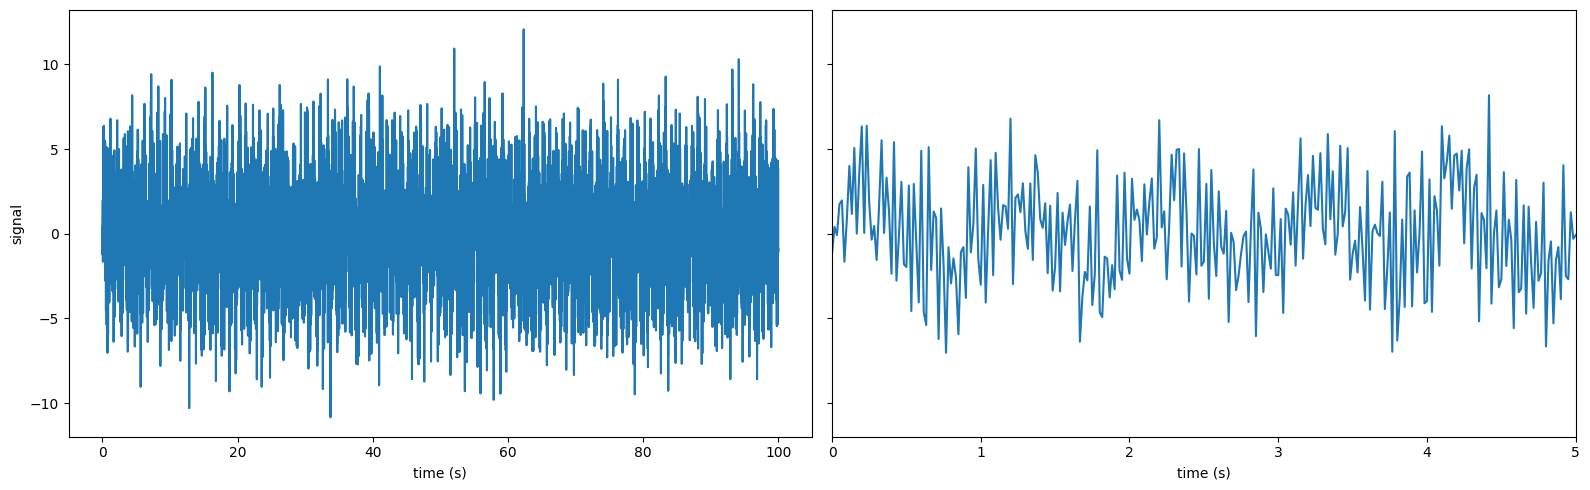

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].plot(t, f_t)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("signal")
axes[1].plot(t, f_t)
axes[1].set_xlim(0, 5)
axes[1].set_xlabel("time (s)")

plt.tight_layout()

### Obliczanie Dyskretnej Transformacji Fouriera (algorytm FFT)
Przechodzimy z dziedziny czasu do dziedziny częstotliwości. Dla ciągu $N$ próbek $(x_0, x_1, \dots, x_{N-1})$ Dyskretna Transformacja Fouriera (DFT) wyraża się wzorem:
$$X_k = \sum_{n=0}^{N-1} x_n e^{-i 2\pi k n / N}$$
Funkcja `fftpack.fft(f_t)` oblicza te wartości za pomocą algorytmu Szybkiej Transformacji Fouriera (FFT) w czasie $O(N \log N)$. Wynikiem jest tablica `F` zawierająca zespolone amplitudy odpowiadające kolejnym przedziałom (tzw. *binom*) częstotliwości.

In [112]:
 F = fftpack.fft(f_t)

### Wyznaczanie osi częstotliwości
Sama tablica `F` zwracana przez `fft` zawiera jedynie amplitudy, ale nie mówi wprost, jakim wartościom w hercach (Hz) odpowiadają poszczególne indeksy. 
Funkcja pomocnicza `fftpack.fftfreq(N, 1.0/f_s)` przyjmuje liczbę próbek $N$ oraz odstęp czasowy między próbkami $\Delta t = 1/f_s$ i zwraca tablicę `f` z przypisanymi częstotliwościami.

In [113]:
 f = fftpack.fftfreq(N, 1.0/f_s)

### Filtrowanie częstotliwości dodatnich (symetria widma)
Wynik transformacji `fft` zawiera zarówno częstotliwości dodatnie, jak i ujemne. Dodatkowo widmo amplitudowe jest idealnie symetryczne względem zera ($|F(\nu)| = |F(-\nu)|$). 

W praktyce ujemna część osi nie wnosi żadnej nowej informacji, dlatego tworzymy maskę logiczną wybierającą tylko nieujemne częstotliwości (`f >= 0`).

In [114]:
 mask = np.where(f >= 0)

### Wizualizacja widma amplitudowego
Prezentujemy obliczone widmo dla częstotliwości dodatnich na trzech wykresach:
* Górny wykres ukazuje pełne widmo od $0$ do $30\text{ Hz}$ (kropka oznacza granicę pasma $B = f_s/2$). Zastosowano tu skalę logarytmiczną $\log(|F|)$, co pozwala zwiększyć kontrast między użytecznym sygnałem a tłem szumowym (tzw. *noise floor*). Od razu widać dwa wyraźne piki przy $1\text{ Hz}$ i $22\text{ Hz}$.
* Środkowy i dolny wykres to przybliżenia okolic $1\text{ Hz}$ oraz $22\text{ Hz}$, na których wykreślono znormalizowaną amplitudę $|F|/N$. Mimo że w dziedzinie czasu sygnał tonął w szumie, w dziedzinie częstotliwości jego składowe harmoniczne są widoczne.

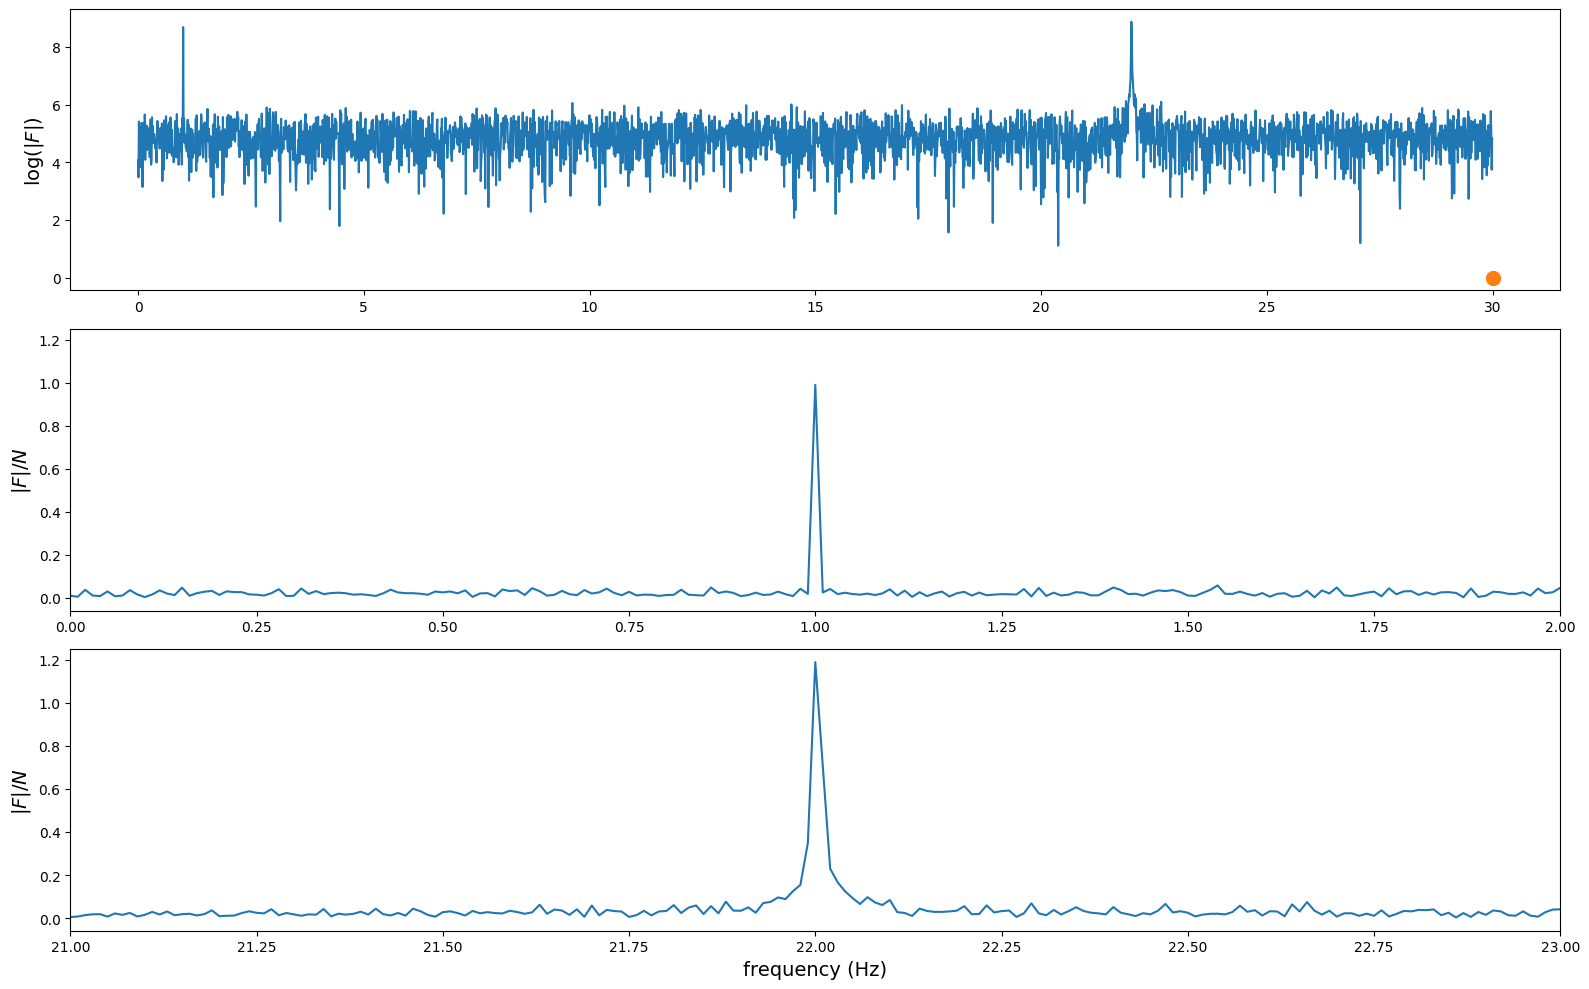

In [115]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
axes[0].plot(f[mask], np.log(abs(F[mask])), label="real")
axes[0].plot(B, 0, "o", markersize=10)
axes[0].set_ylabel(r"$\log(|F|)$", fontsize=14)
axes[1].plot(f[mask], abs(F[mask]) / N, label="real")
axes[1].set_xlim(0, 2)
axes[1].set_ylabel("$|F|/N$", fontsize=14)
axes[2].plot(f[mask], abs(F[mask]) / N, label="real")
axes[2].set_xlim(21, 23)
axes[2].set_xlabel("frequency (Hz)", fontsize=14)
axes[2].set_ylabel("$|F|/N$", fontsize=14)

plt.tight_layout()

## 2. Filtracja w dziedzinie częstotliwości (Frequency-Domain Filter)

Skoro funkcja `fft` pozwala przejść z dziedziny czasu do dziedziny częstotliwości, to funkcja odwrotna `ifft` (Inverse FFT) pozwala z powrotem zrekonstruować sygnał czasowy na podstawie jego widma.
Daje nam to możliwość zmodyfikacji widma częstotliwościowego przed wykonaniem transformacji odwrotnej, realizując w ten sposób filtrację sygnału (np. wycinając niechciane pasma częstotliwości lub szum).

### Zastosowanie filtra dolnoprzepustowego i odwrotnej transformacji (IFFT)
W poniższej komórce:
1. Mnożymy widmo `F` przez maskę logiczną `(abs(f) < 2)`. Działa to jak filtr dolnoprzepustowy o częstotliwości odcięcia $2\text{ Hz}$: wszystkie składowe poniżej $2\text{ Hz}$ zostają zachowane, a wszystkie wyższe częstotliwości są zerowane.
2. Za pomocą funkcji `fftpack.ifft(F_filtered)` obliczamy odwrotną transformację Fouriera:
$$x_n = \frac{1}{N} \sum_{k=0}^{N-1} X_k e^{i 2\pi k n / N}$$
Przywraca ona przefiltrowany sygnał z powrotem do dziedziny czasu.

In [116]:
 F_filtered = F * (abs(f) < 2)
 f_t_filtered = fftpack.ifft(F_filtered)

### Porównanie sygnału oryginalnego i przefiltrowanego
Zestawiamy na wykresie oryginalny, zaszumiony sygnał oraz sygnał po odfiltrowaniu częstotliwości powyżej $2\text{ Hz}$. 
Szybkie oscylacje oraz większość szumu zniknęły – otrzymaliśmy gładką falę sinusoidalną o okresie $1\text{ s}$.

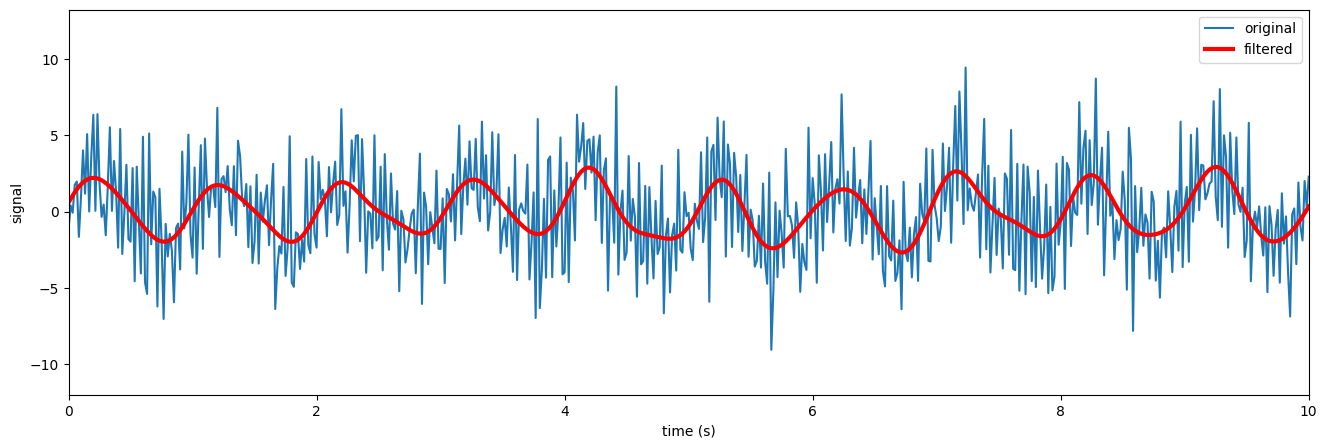

In [117]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(t, f_t, label="original")
ax.plot(
    t, f_t_filtered.real, color="red", lw=3, label="filtered"
)  # bierzemy część rzeczywistą `.real`, ponieważ `ifft` zwraca typ zespolony z zerową częścią urojoną
ax.set_xlim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend()

## 3. Okienkowanie sygnału (Windowing) i przeciek widma

W poprzednim przykładzie zastosowaliśmy FFT bezpośrednio do surowego sygnału. W praktyce często można znacząco poprawić jakość i kontrast widma, mnożąc sygnał przed transformacją przez funkcję okna – funkcję, która gładko wygasza amplitudę sygnału do zera na początku i na końcu przedziału próbkowania.

*Dlaczego stosujemy okienkowanie?* Dyskretna Transformacja Fouriera (DFT) z założenia traktuje analizowany wycinek sygnału tak, jakby był on nieskończenie powtarzanym sygnałem okresowym. Jeśli w badanym sygnale występują składowe, których okres nie mieści się całkowitą liczbę razy w czasie pomiaru $T$, to na styku końca jednego okresu pomiarowego i początku „kolejnego” powstaje sztuczna nieciągłość (skok wartości). 
W dziedzinie częstotliwości taki skok objawia się jako tzw. przeciek widma (spectral leakage) – zamazuje to obraz i utrudniaja wykrycie słabszych sygnałów. Przemnożenie sygnału przez funkcję okna łagodzi przejścia na krańcach przedziału i redukuje ten problem.

### Porównanie funkcji okien
Moduł `scipy.signal.windows` udostępnia wiele gotowych funkcji okien, m.in. Blackmana, Hanna, Hamminga, Gaussa (z regulowanym odchyleniem standardowym) oraz Kaisera. 
Poniższy wykres pokazuje ich kształt dla próbki o długości $N = 100$. 
W większości zastosowań można ich używać zamiennie.

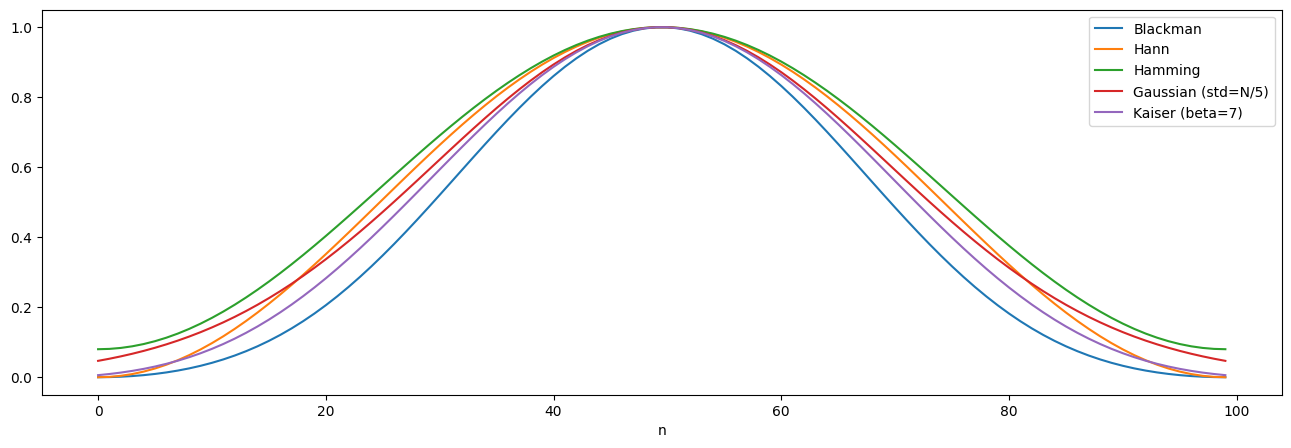

In [118]:
fig, ax = plt.subplots(1, 1, figsize=(16, 5))
N = 100
ax.plot(signal.windows.blackman(N), label="Blackman")
ax.plot(signal.windows.hann(N), label="Hann")
ax.plot(signal.windows.hamming(N), label="Hamming")
ax.plot(signal.windows.gaussian(N, N / 5), label="Gaussian (std=N/5)")
ax.plot(signal.windows.kaiser(N, 7), label="Kaiser (beta=7)")
ax.set_xlabel("n")
ax.legend(loc=0)

## Przykład 1 - Rzeczywiste dane czasowe

Przechodzimy do przykładu praktycznego na danych rzeczywistych - Analiza widmowa biosygnałów z bazy MIMIC

Na przykładzie rzeczywistego fotopletyzmogramu (sygnału tętna `PLETH`) pobranego od pacjenta z OIOM-u, zobaczymy, jak można wyciągnąć częstotliwość uderzeń serca.

In [119]:
df = pd.read_csv("03900001_biosignals.csv")

f_s = 125.0
N = int(10 * f_s)  # wycinamy 10 sekund sygnału


Aby przekazać dane do funkcji z modułu `fftpack`, wyciągamy z obiektu tablice NumPy: wektor wartości sygnału tętna `pleth_signal` oraz odpowiadający mu wektor czasu `time` wyrażony w sekundach.

In [120]:
pleth_signal = df["PLETH"].values[:N]
time = np.arange(N) / f_s

#### Utworzenie okna Blackmana
Generujemy tablicę z wagami okna Blackmana o długości dokładnie równej liczbie naszych pomiarów.

In [121]:
window = signal.windows.blackman(N)

#### Nałożenie okna na sygnał
Mnożymy oryginalny szereg czasowy `pleth_signal` przez funkcję okna `window`. 
Na wykresie widać, że zokienkowany sygnał zachowuje oscylacje w środkowej części przedziału, ale na brzegach łagodnie dąży do zera. Eliminuje to sztuczny skok wartości między końcem a początkiem okresu pomiarowego, co zapobiegnie rozmyciu widma podczas obliczania FFT.

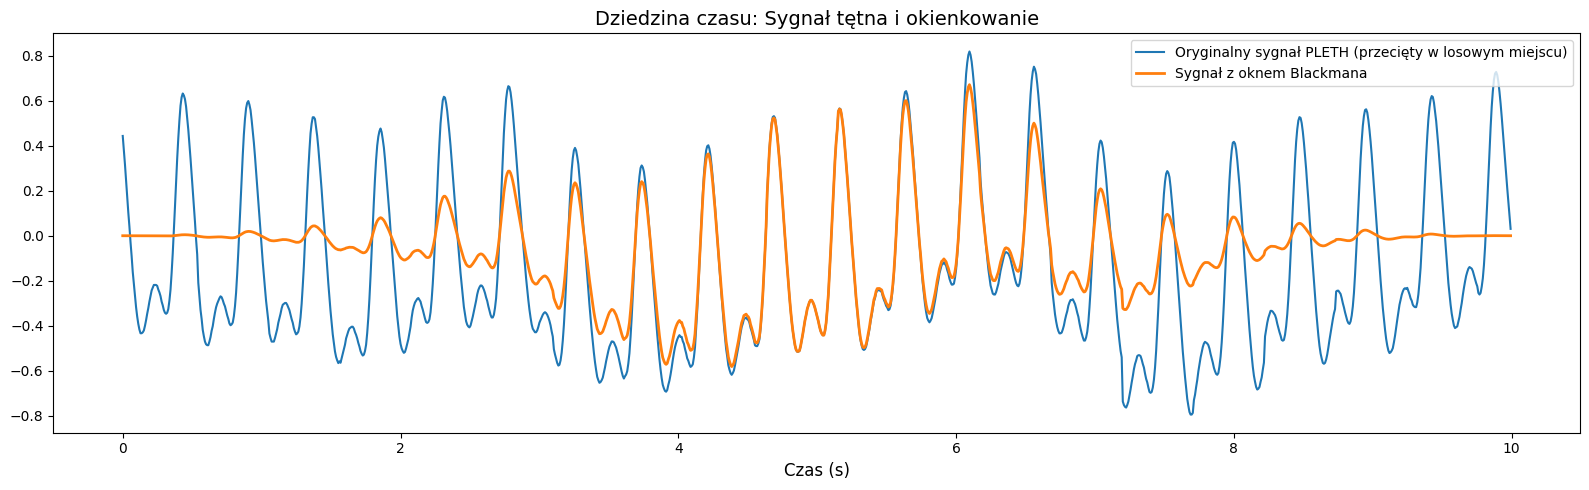

In [122]:
pleth_windowed = pleth_signal * window

fig, ax = plt.subplots(1, 1, figsize=(16, 5))
ax.plot(
    time, pleth_signal, label="Oryginalny sygnał PLETH (przecięty w losowym miejscu)"
)
ax.plot(time, pleth_windowed, label="Sygnał z oknem Blackmana", linewidth=2)
ax.set_title("Dziedzina czasu: Sygnał tętna i okienkowanie", fontsize=14)
ax.set_xlabel("Czas (s)", fontsize=12)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

#### Obliczenie transformacji FFT zokienkowanego sygnału temperatury
Wykonujemy transformację `fftpack.fft` na sygnale przemnożonym przez okno i wyznaczamy odpowiadające jej częstotliwości za pomocą `fftpack.fftfreq`.

In [123]:
F = fftpack.fft(pleth_windowed)
f = fftpack.fftfreq(N, 1.0 / f_s)
mask = np.where(f >= 0)

Z wykresu możemy wyciągnąć kilka kluczowych wniosków:

* Częstotliwość podstawowa: Na wykresie widzimy najwyższy i najwyraźniejszy pik (dominującą składową) w okolicach 126 - 132 BPM. Jest to wysokie tętno.

* Wyższe harmoniczne: Poza głównym pikiem widoczne są również mniejsze prążki będące jego wielokrotnościami (ok. $4.2 - 4.4\text{ Hz}$ oraz ok. $6.3 - 6.6\text{ Hz}$). Ich obecność wynika z tego, że rzeczywista fala tętna nie jest idealną, gładką sinusoidą.

* Redukcja przecieku widma (Spectral Leakage): Pomiędzy pikami amplituda opada niemal do zera, co oznacza bardzo czysty sygnał z niskim poziomem zniekształceń. Nałożenie okna Blackmana w dziedzinie czasu gładko wygasiło ucięte brzegi naszego 10-sekundowego fragmentu.

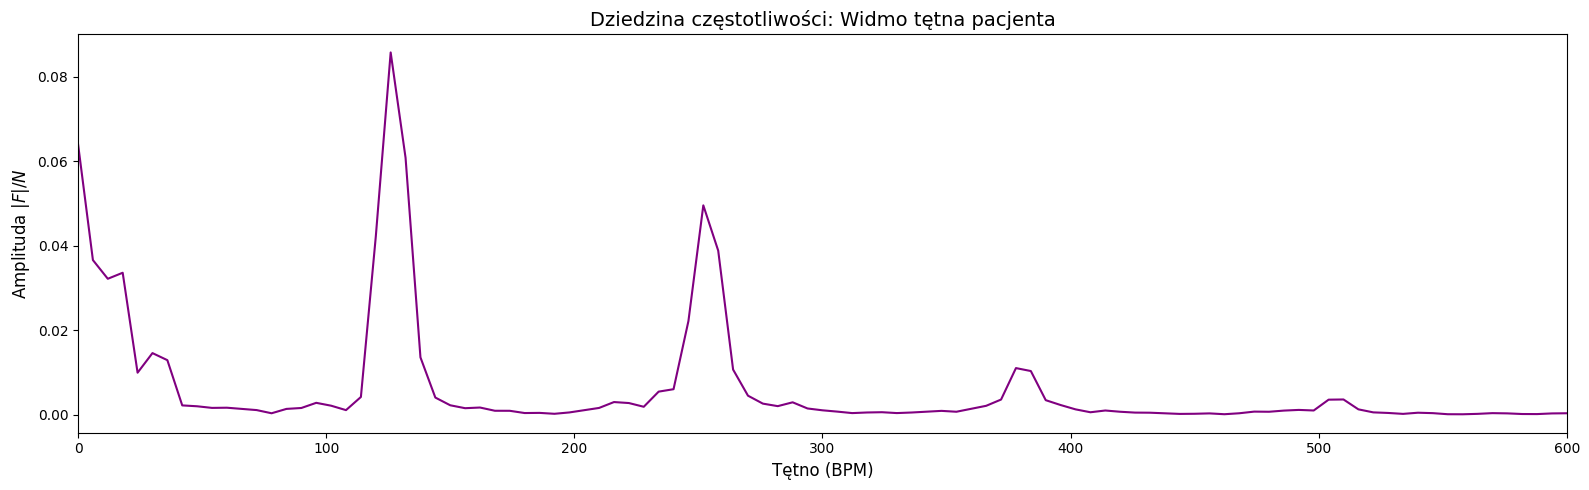

In [124]:
bpm = f[mask] * 60  # przeliczamy częstotliwość z Hz na BPM (1 Hz = 60 BPM)

fig, ax = plt.subplots(1, 1, figsize=(16, 5))
ax.plot(bpm, abs(F[mask]) / N, color="purple")
ax.set_xlim(0, 600)
ax.set_title("Dziedzina częstotliwości: Widmo tętna pacjenta", fontsize=14)
ax.set_xlabel("Tętno (BPM)", fontsize=12)
ax.set_ylabel(r"Amplituda $|F|/N$", fontsize=12)

plt.tight_layout()
plt.show()

### Przykład 2

## 4. Spektrogram – analiza czasowo-częstotliwościowa

W przypadku wielu sygnałów (szczególnie muzyki czy mowy) obliczenie jednego widma FFT dla całego nagrania naraz jest mało użyteczne. Muzyka na krótkich skalach czasowych (ułamków sekund) jest niemal okresowa, ale na dłuższej skali zmienia się w czasie.

Rozwiązaniem jest obliczanie transformacji FFT w przesuwnym oknie czasowym (tzw. Short-Time Fourier Transform – STFT). Dzielimy długi sygnał na krótkie, następujące po sobie segmenty i dla każdego z nich osobno liczymy widmo (z funkcją okna). Otrzymujemy w ten sposób widmo zależne od czasu, które można przedstawić na dwuwymiarowej mapie ciepła nazywanej spektrogramem.

### Wczytanie nagrania audio z pliku WAV
Wczytujemy próbkę dźwięku gitary za pomocą `io.wavfile.read`. Funkcja ta zwraca krotkę składającą się z dwóch elementów:
* `sample_rate` – częstotliwość próbkowania (w Hz),
* `data` – tablica NumPy zawierająca zapisane natężenie dźwięku (amplitudę w kolejnych chwilach czasu).

In [125]:
 sample_rate, data = io.wavfile.read("guitar.wav")

### Sprawdzenie częstotliwości próbkowania
Sprawdzamy wartość `sample_rate`. Wynik $44100\text{ Hz}$ to klasyczny standard jakości CD – oznacza, że w każdej sekundzie nagrania zarejestrowano $44100$ próbek dźwięku.

In [126]:
sample_rate

44100

### Sprawdzenie kształtu tablicy z danymi audio
Właściwość `data.shape` zwraca `(540006, 2)`. Oznacza to, że nagranie liczy $1\,080\,012$ próbek czasowych i zostało zarejestrowane w stereo (posiada 2 kanały audio: lewy i prawy).

In [127]:
data.shape

(226634, 2)

### Konwersja ze stereo do mono i czas trwania nagrania
Dla uproszczenia analizy widmowej uśredniamy oba kanały wzdłuż drugiej osi (w praktyce, na tym nagraniu oba kanały są niemal identyczne), uzyskując pojedynczy sygnał mono. 
Następnie dzielimy całkowitą liczbę próbek przez częstotliwość próbkowania (`data.shape[0] / sample_rate`).

In [128]:
data = data.mean(axis=1)
data.shape[0] / sample_rate

5.139092970521542

### Ustalenie rozmiaru pojedynczego okna czasowego
Zamiast analizować całe nagranie naraz, podzielimy sygnał na krótkie, fragmenty ($\Delta T = 0.1\text{ s}$). 

In [129]:
N = int(sample_rate / 10.0)

### Przygotowanie osi czasu, częstotliwości i maski pasma dla jednego segmentu
Dla pojedynczego, półsekundowego wycinka ($N$ próbek):
1. Wyliczamy tablicę częstotliwości `f` za pomocą `fftfreq`.
2. Tworzymy lokalną oś czasu `t` od $0$ do $0.5\text{ s}$.
3. Definiujemy maskę logiczną `mask` wybierającą tylko dodatnie częstotliwości poniżej $1400\text{ Hz}$ (`(f > 0) * (f < 1400)`), ponieważ w tym paśmie skupiają się podstawowe tony gitary. W ten sposób wysokotonowy szum tła zostanie zignorowany.

In [130]:
f = fftpack.fftfreq(N, 1.0 / sample_rate)
t = np.linspace(0, 0.5, N)
mask = (f > 0) * (f < 1400)

### Obliczenie FFT dla pierwszego półsekundowego fragmentu
Pobieramy pierwsze $N$ próbek nagrania (`subdata = data[:N]`) i wyznaczamy dla nich transformatę Fouriera `F`.

In [131]:
subdata = data[:N]
F = fftpack.fft(subdata)

### Wizualizacja w dziedzinie czasu i częstotliwości

* Górny wykres ukazuje przebieg fali dźwiękowej. Silne "uderzenie" i największe wahania amplitudy widoczne w okolicach $0.1\text{ s}$ sugerują moment szarpnięcia struny. Po tym momencie sygnał powoli zaczyna tracić swoją energię. Analiza w dziedzinie czasu mówi nam kiedy wystąpił głośny dźwięk, ale nie jakie nuty zostały zagrane.

* Dolny wykres mówi o dziedzinie częstotliwości. Dyskretna Transformata Fouriera (FFT) odkrywa przed nami to, było ukryte w sygnale z górnego panelu. Wykres dekomponuje skomplikowany dźwięk na proste fale. Zamiast chaotycznego szumu, widzimy wyraźne piki (prążki), które oznaczają dominujące częstotliwości.
     * Zdecydowanie najwyższy, dominujący pik znajduje się tuż przed wartością $250\text{ Hz}$.
     * Ograniczenie widoku do $1400\text{ Hz}$ jest tutaj celowe – w tym przedziale mieszczą się częstotliwości podstawowe gitary (tony podstawowe oscylują ok. $82\text{ Hz}$ - $1300\text{ Hz}$).

Text(0.5, 0, 'Frequency (Hz)')

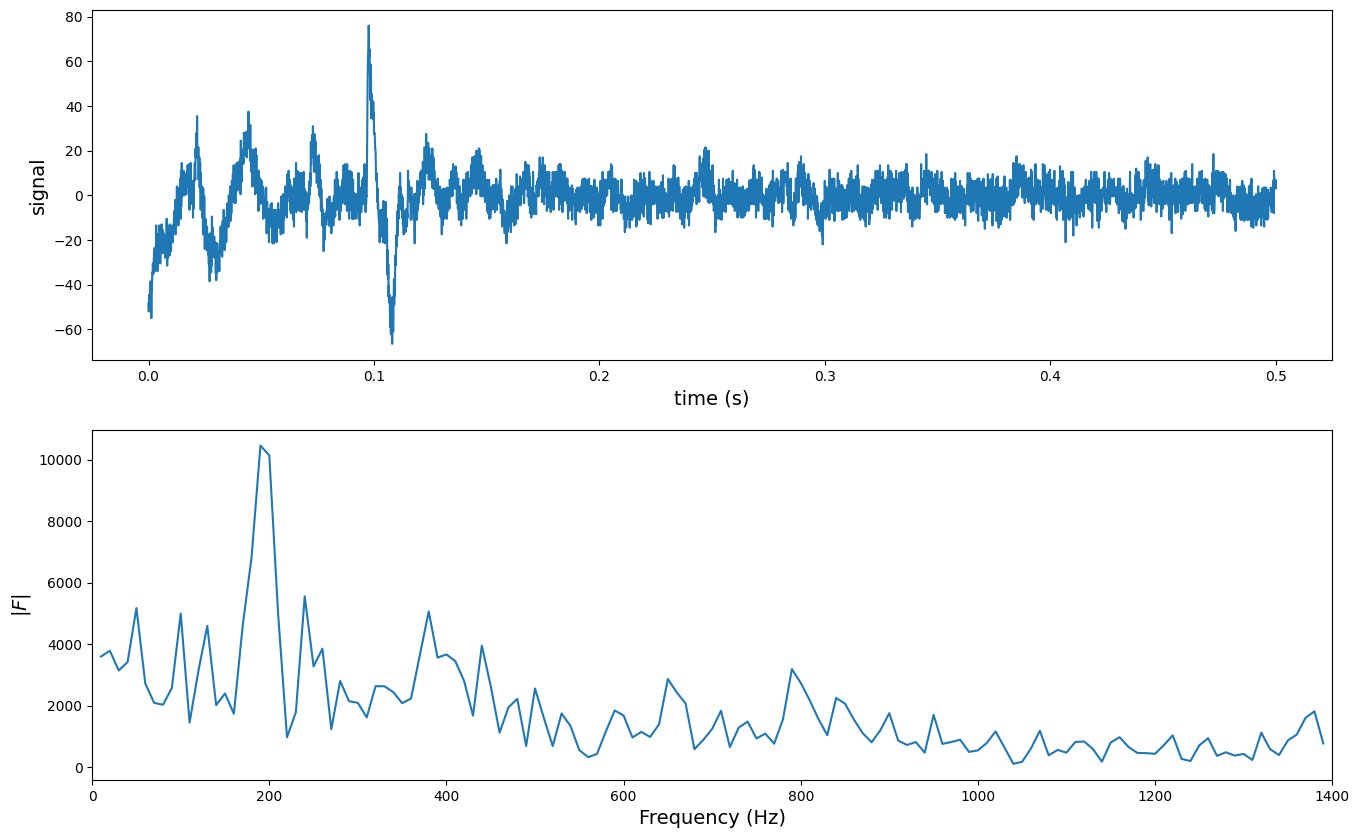

In [132]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
axes[0].plot(t, subdata)
axes[0].set_ylabel("signal", fontsize=14)
axes[0].set_xlabel("time (s)", fontsize=14)
axes[1].plot(f[mask], abs(F[mask]))
axes[1].set_xlim(
    0, 1400
)  # ponieważ najwyższy dźwięk grający ton podstawowy to ok. 1000 - 1300 Hz. (powyżej 1300 Hz znajdują się już tylko wyższe harmoniczne - które nadają barwę, ale są słabsze - oraz szum)
axes[1].set_ylabel("$|F|$", fontsize=14)
axes[1].set_xlabel("Frequency (Hz)", fontsize=14)

### Przygotowanie macierzy pod pełny spektrogram
Teraz chcemy powtórzyć powyższą analizę dla wszystkich kolejnych półsekundowych segmentów nagrania:
* `n_max` to całkowita liczba pełnych półsekundowych odcinków mieszczących się w nagraniu.
* `f_values` to liczba punktów częstotliwości spełniających warunek maski.
* Inicjalizujemy dwuwymiarową tablicę zer `spectogram_data` o wymiarach `(n_max, f_values)`, w której każdy wiersz będzie reprezentował widmo kolejnego odcinka czasu.

In [133]:
n_max = int(data.shape[0] / N)
f_values = np.sum(mask)
spectogram_data = np.zeros((n_max, f_values))

### Zastosowanie okna Blackmana dla wycinków audio
Aby zredukować przeciek widma na granicach naszych półsekundowych wycinków i poprawić kontrast spektrogramu, przygotowujemy okno Blackmana o długości równej jednemu segmentowi `subdata`.

In [134]:
window = signal.windows.blackman(len(subdata))

### Obliczenie widma w pętli po kolejnych oknach czasowych
W pętli przechodzimy przez wszystkie `n_max` segmentów nagrania:
1. Wycinamy kolejny fragment o długości $N$ próbek.
2. Mnożymy go przez okno Blackmana (`subdata * window`).
3. Obliczamy transformatę `fft`.
4. Zapisujemy logarytm modułu widma `np.log(abs(F[mask]))` w odpowiednim wierszu macierzy `spectogram_data`.

In [135]:
for n in range(0, n_max):
    subdata = data[(N * n) : (N * (n + 1))]
    F = fftpack.fft(subdata * window)
    spectogram_data[n, :] = np.log(abs(F[mask]))

### Wyświetlenie spektrogramu jako mapy ciepła (Heatmap)
Spektrogram łączy w sobie analizę w dziedzinie czasu i częstotliwości, pozwalając zaobserwować, jak zmieniają się poszczególne tony w trakcie trwania nagrania. Z wykresu można wydedukować:
* Śledzenie melodii w czasie: Na wykresie widzimy wyraźne, ciągłe czerwone "ścieżki" obrazujące graną melodię. Kiedy czerwona linia przesuwa się płynnie w lewo lub w prawo, oznacza to zmianę wysokości dźwięku.
* Struktura harmoniczna: Prążki bardziej po lewej to tony podstawowe (właściwa nuta), natomiast równoległe do nich czerwone pręgi po prawej stronie to wyższe harmoniczne, nadające gitarze jej charakterystyczną barwę

Text(0.5, 0, 'Frequency (Hz)')

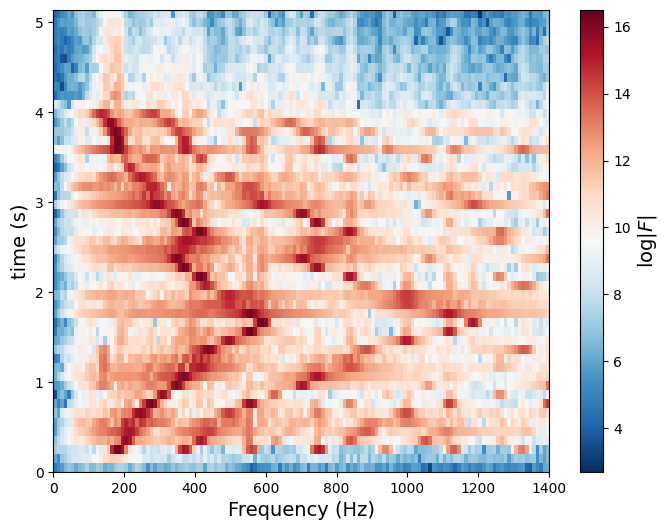

In [136]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
p = ax.imshow(
    spectogram_data,
    origin="lower",
    extent=(0, 1400, 0, data.shape[0] / sample_rate),
    aspect="auto",
    cmap=mpl.cm.RdBu_r,
)
cb = fig.colorbar(p, ax=ax)
cb.set_label(r"$\log|F|$", fontsize=14)
ax.set_ylabel("time (s)", fontsize=14)
ax.set_xlabel("Frequency (Hz)", fontsize=14)

___________________________________________________________________________________________________________________

## 5. Filtry sygnałowe (Signal Filters)

Jednym z głównych celów przetwarzania sygnałów jest modyfikowanie ich charakterystyk – np. redukcja szumu, nakładanie efektów dźwiękowych w audio czy wyostrzanie/rozmywanie obrazów. 
Poznaliśmy już filtrację w dziedzinie częstotliwości (FFT $\rightarrow$ wycięcie pasma $\rightarrow$ IFFT). Ma ona jednak istotną wadę praktyczną: wymaga zbuforowania całego sygnału (lub dużych jego bloków), przez co trudno ją stosować w czasie rzeczywistym na strumieniu danych (np. podczas rozmowy na żywo). W takich zastosowaniach znacznie lepiej sprawdzają się filtry działające bezpośrednio w dziedzinie czasu.

### Filtry splotowe (Convolution Filters)

Z twierdzenia o splocie wynika fundamentalna własność transformacji Fouriera: odwrotna transformacja Fouriera iloczynu dwóch funkcji w dziedzinie częstotliwości jest równa splotowi ich odwrotnych transformat w dziedzinie czasu.

Oznacza to, że zamiast mnożyć widmo sygnału $X_k$ przez charakterystykę filtra $H_k$, możemy obliczyć odwrotną transformatę samego filtra $h_m = \mathcal{F}^{-1}(H_k)$ (nazywaną jądrem splotu lub odpowiedzią impulsową) i wykonać splot dyskretny bezpośrednio w dziedzinie czasu:
$$y_n = \sum_{k=-\infty}^{\infty} x_k h_{n-k}$$
gdzie $x_k$ to sygnał wejściowy, a $y_n$ to przefiltrowany sygnał wyjściowy.

### Implementacja filtra splotowego i porównanie z filtracją w dziedzinie częstotliwości
Wracamy na chwilę do naszego pierwszego symulowanego sygnału z częstotliwościami $1\text{ Hz}$ i $22\text{ Hz}$. Chcemy pokazać, że oba podejścia (filtracja widmowa i splot w dziedzinie czasu) dają identyczny wynik.
Do tego obliczymy odwrotną transformatę Fouriera `ifft(H)` na wygenerowanym sygnale i używamy `fftpack.fftshift`, aby wyśrodkować odpowiedź impulsową – otrzymujemy w ten sposób jądro splotu `h`.

In [137]:
# ponownie tworzymy sygnał
t = np.linspace(0, T, N)
f_t = signal_samples(t)


# klasyczna filtracja w dziedzinie częstotliwości (FFT -> modyfikacja -> IFFT)
f = fftpack.fftfreq(N, t[1] - t[0])
F = fftpack.fft(f_t)
f_t_filtered = fftpack.ifft(F * (abs(f) < 2))


# filtracja w dziedzinie czasu za pomocą splotu (Convolution)
H = abs(f) < 2  # filtr dolnoprzepustowy
h = fftpack.fftshift(fftpack.ifft(H))  # wyznaczamy jądro splotu
f_t_filtered_conv = signal.convolve(f_t, h, mode="same")  # wykonujemy splot

### Wizualizacja filtra częstotliwościowego, jądra splotu i wyników filtracji
* Lewy górny wykres pokazuje charakterystyke filtra `H` w dziedzinie częstotliwości (przepuszcza pasmo $[-2, 2]\text{ Hz}$).
* Prawy górny wykres przedstawia odpowiadające mu jądro splotu `h` w dziedzinie czasu (odpowiedź impulsowa po wyśrodkowaniu).
* Dolny panel to nałożone na siebie przebiegi czasowe: sygnał przefiltrowany w dziedzinie częstotliwości (czerwona linia ciągła) oraz sygnał przefiltrowany splotem w dziedzinie czasu (niebieska linia przerywana). Obie krzywe idealnie się pokrywają!

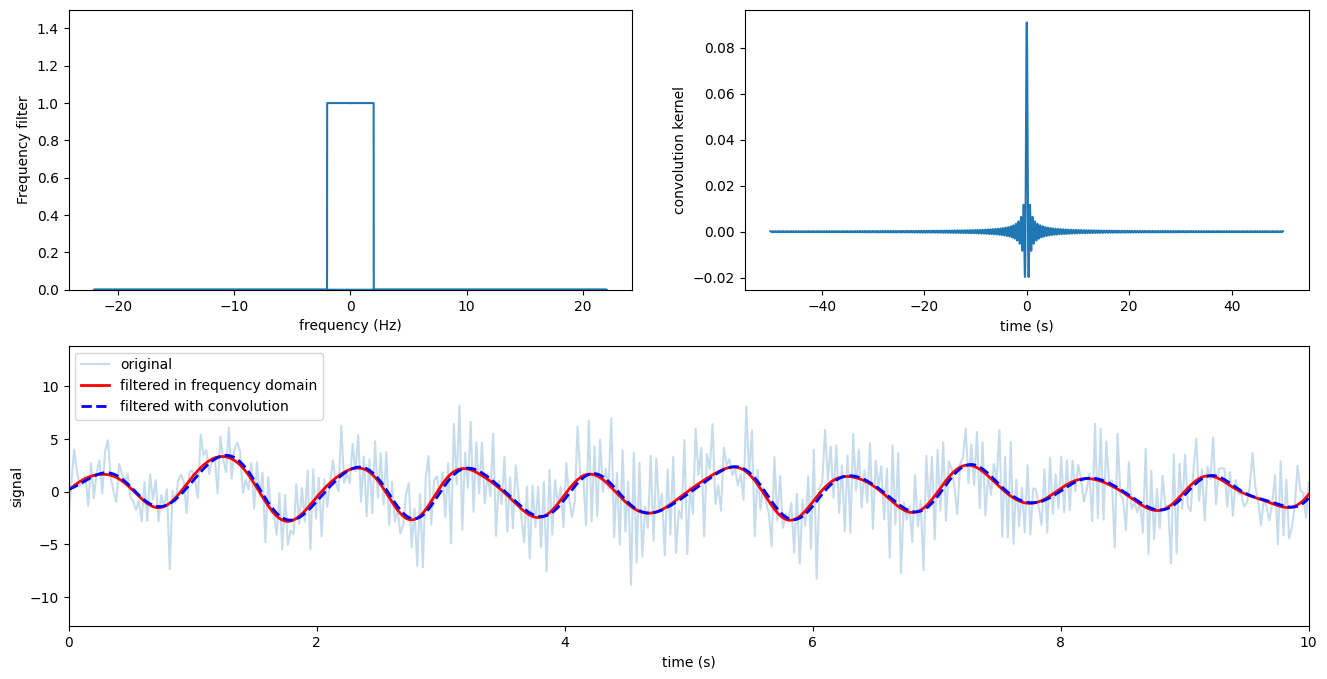

In [138]:
fig = plt.figure(figsize=(16, 8))
ax = plt.subplot2grid((2, 2), (0, 0))
ax.plot(f, H)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("Frequency filter")
ax.set_ylim(0, 1.5)
ax = plt.subplot2grid((2, 2), (0, 1))
ax.plot(t - t[-1] / 2.0, h.real)
ax.set_xlabel("time (s)")
ax.set_ylabel("convolution kernel")
ax = plt.subplot2grid((2, 2), (1, 0), colspan=2)
ax.plot(t, f_t, label="original", alpha=0.25)
ax.plot(t, f_t_filtered.real, "r", lw=2, label="filtered in frequency domain")
ax.plot(t, f_t_filtered_conv.real, "b--", lw=2, label="filtered with convolution")
ax.set_xlim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend(loc=2)

Ogólny filtr splotowy ma jednak pewną wadę: jego jądro $h$ rozciąga się w obie strony osi czasu, co oznacza, że wartość wyjściowa $y_n$ w chwili $n$ zależy również od przyszłych wartości sygnału wejściowego $x_k$. Taki filtr nazywamy nieprzyczynowym (non-causal) – nie da się go zrealizować w czasie rzeczywistym bez opóźnienia i buforowania przyszłości.

## 6. Filtry cyfrowe FIR oraz IIR
W wielu urządzeniach (np. czujnikach, słuchawkach z redukcją szumów) sygnał napływa na żywo. Nie znamy przyszłości. Potrzebujemy filtrów przyczynowych, które na bieżąco analizują tylko to, co już się wydarzyło.

Do tego służą filtry w dziedzinie czasu:
1. **Filtry FIR (Finite Impulse Response – o skończonej odpowiedzi impulsowej):** działa jak bardzo inteligentna "średnia krocząca". Wynik to po prostu suma obecnej i kilku poprzednich próbek przemnożonych przez odpowiednie wagi. Jest super stabilny, ale potrzebuje wielu współczynników (dużej pamięci), żeby dobrze filtrować.
2. **Filtry IIR (Infinite Impulse Response – o nieskończonej odpowiedzi impulsowej):** działa podobnie, ale dodatkowo podgląda swoje własne poprzednie wyniki (sprzężenie zwrotne). Dzięki temu odcina niechciane częstotliwości bardzo agresywnie, używając tylko kilku współczynników, ale może zaburzać fazę (kształt) sygnału.

Matematycznie zapisujemy to tak:

1. **Filtry FIR**
   $$y_n = \sum_{k=0}^{M} b_k x_{n-k}$$
   Wyjście $y_n$ zależy wyłącznie od bieżącej próbki oraz skończonej liczby $M$ przeszłych próbek wejścia $x_{n-k}$. Filtr ten jest zawsze przyczynowy i bezwarunkowo stabilny.

2. **Filtry IIR**
   $$a_0 y_n = \sum_{k=0}^{M} b_k x_{n-k} - \sum_{k=1}^{N} a_k y_{n-k}$$
   Oprócz przeszłych próbek wejścia wykorzystują one także przeszłe wartości wyjścia $y_{n-k}$ (człon sprzężenia zwrotnego / rekurencji). Pozwala to uzyskać bardzo ostre charakterystyki filtracji przy znacznie mniejszej liczbie współczynników niż w filtrach FIR.

Na naszym pierwotnym wygenerowanym przez nas sygnale, na którym już budowaliśmy filtrację w dziedzinie częstotliwości oraz filtr konwolucyjny, zbudujmy teraz FIR i IIR. 

In [139]:
from scipy.signal import lfilter, filtfilt

# --- WSPÓŁCZYNNIKI DO MANIPULACJI - WSPÓLNE DLA WIELU WYKRESÓW. DO MANIPULACJI ---

cutoff_hz = 5
num_taps = 50  # Liczba współczynników filtra FIR

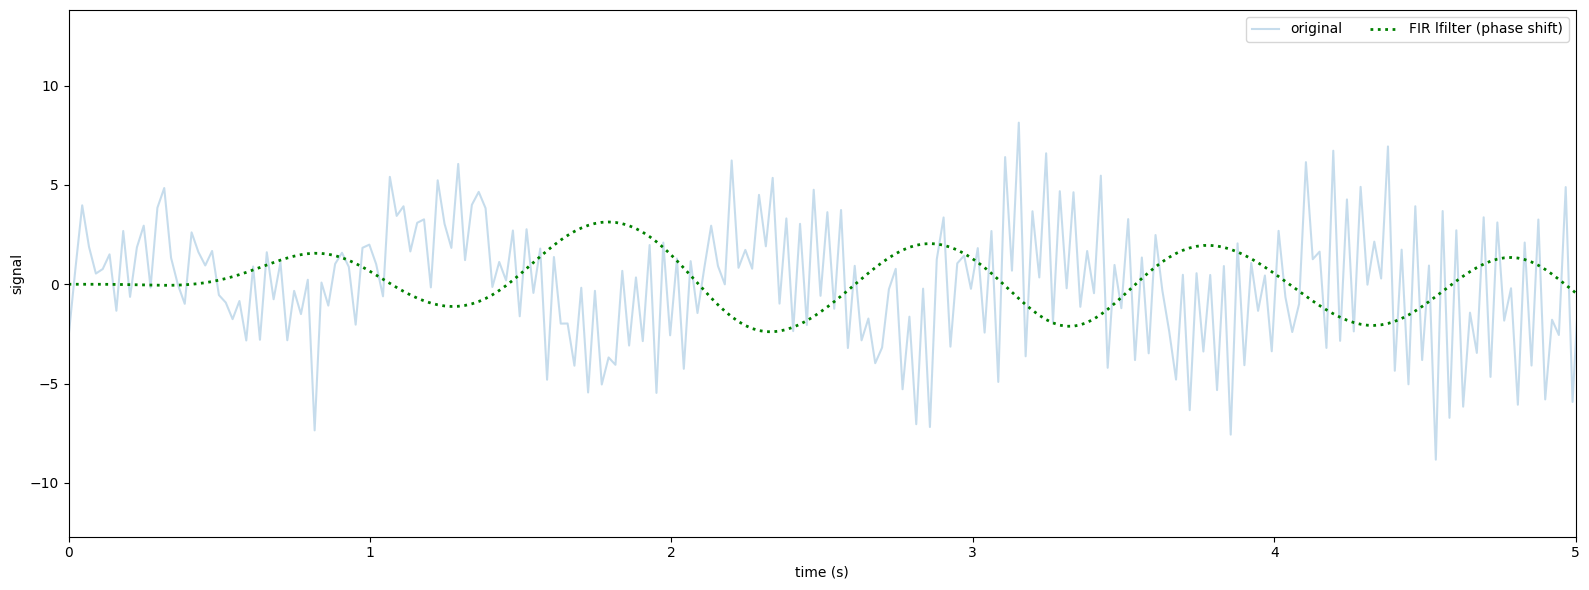

In [ ]:
# FIR
# Współczynniki dla filtru FIR (np. z scipy.signal.firwin)
b_fir = signal.firwin(
    num_taps, cutoff=cutoff_hz, fs=f_s, window="hamming"
)  
a_fir = 1.0  # dla filtrów FIR mianownik to zawsze 1

# --- FILTRACJA ---

# Za pomocą lfilter (filtracja przyczynowa, wprowadza opóźnienie fazowe)
f_t_fir_lfilter = lfilter(b_fir, a_fir, f_t)

# --- WYKRES ---
fig, ax = plt.subplots(figsize=(16, 6))

# Sygnał oryginalny
ax.plot(t, f_t, label="original", alpha=0.25)

ax.plot(
    t,
    f_t_fir_lfilter,
    color="green",
    linestyle=":",
    lw=2,
    label="FIR lfilter (phase shift)",
)

ax.set_xlim(0, 5)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend(loc="upper right", ncol=2)

plt.tight_layout()
plt.show()

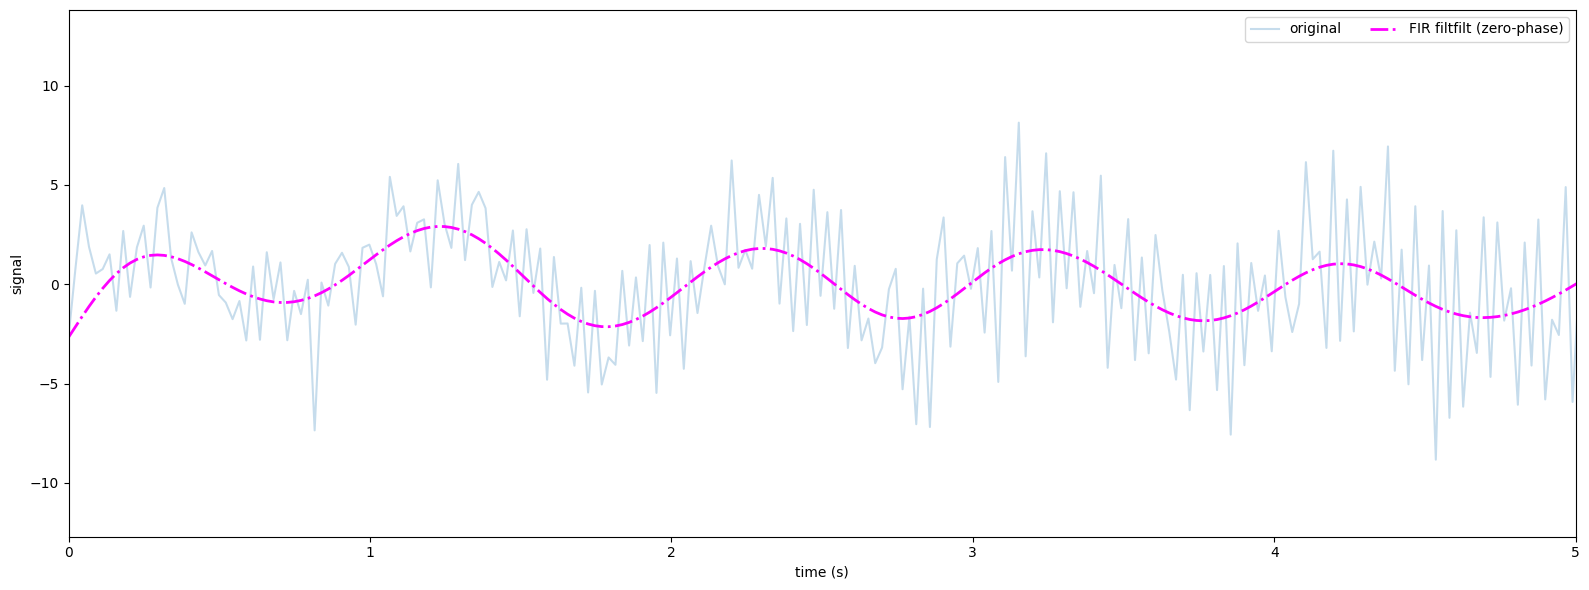

In [ ]:
# FIR z filtfilt
# b_fir, a_fir zostają bez zmian

# --- FILTRACJA ---
# za pomocą filtfilt (filtracja zerofazowa - sygnał przechodzi w przód i w tył)
f_t_fir_filtfilt = filtfilt(b_fir, a_fir, f_t)

# --- WYKRES ---
fig, ax = plt.subplots(figsize=(16, 6))

# Sygnał oryginalny
ax.plot(t, f_t, label="original", alpha=0.25)

ax.plot(
    t,
    f_t_fir_filtfilt,
    color="magenta",
    linestyle="-.",
    lw=2,
    label="FIR filtfilt (zero-phase)",
)

ax.set_xlim(0, 5)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend(loc="upper right", ncol=2)

plt.tight_layout()
plt.show()

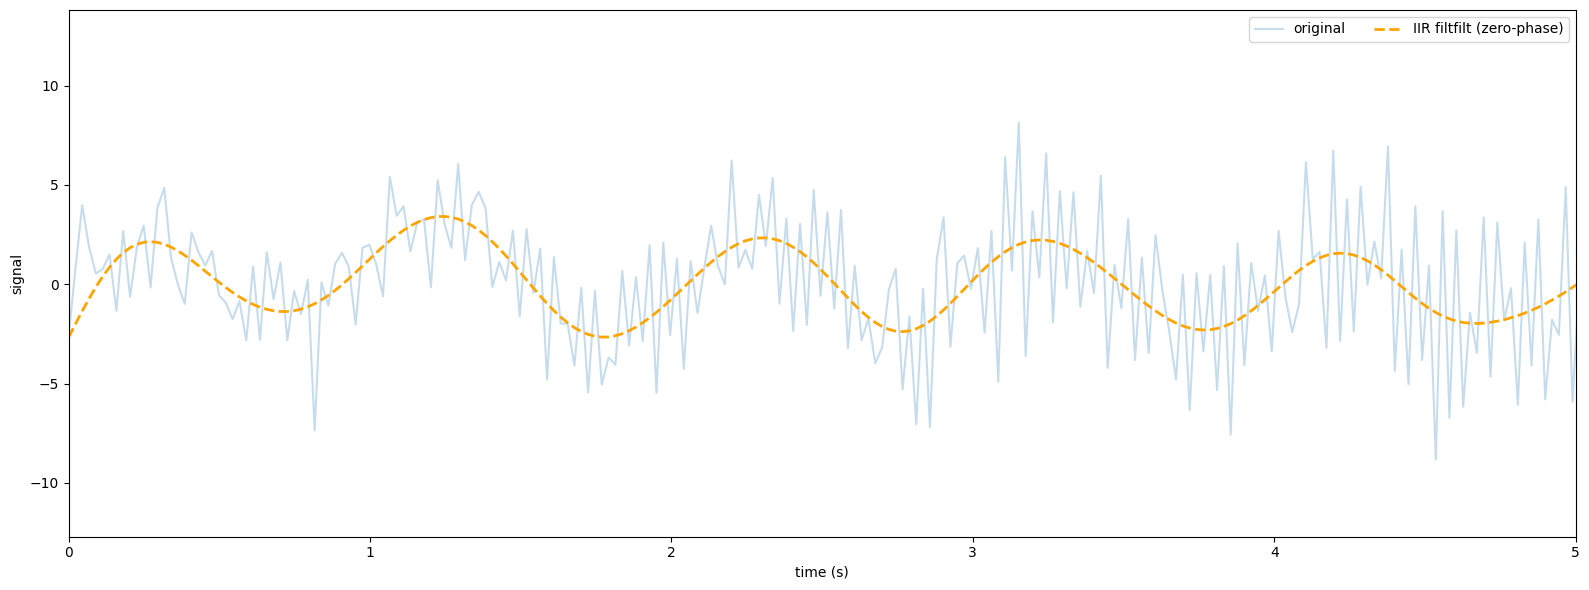

In [ ]:
# IIR
# Współczynniki dla filtru IIR (np. z scipy.signal.butter, iirfilter)
b_iir, a_iir = signal.butter(4, cutoff_hz, fs=f_s, btype="low") #sprawdź, co się dzieje, gdy btype = "highpass"

# --- FILTRACJA ---
# za pomocą filtfilt (filtracja zerofazowa)
f_t_iir_filtfilt = filtfilt(b_iir, a_iir, f_t)

# --- WYKRES ---
fig, ax = plt.subplots(figsize=(16, 6))

# Sygnał oryginalny
ax.plot(t, f_t, label="original", alpha=0.25)
ax.plot(
    t,
    f_t_iir_filtfilt,
    color="orange",
    linestyle="--",
    lw=2,
    label="IIR filtfilt (zero-phase)",
)

ax.set_xlim(0, 5)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend(loc="upper right", ncol=2)

plt.tight_layout()
plt.show()

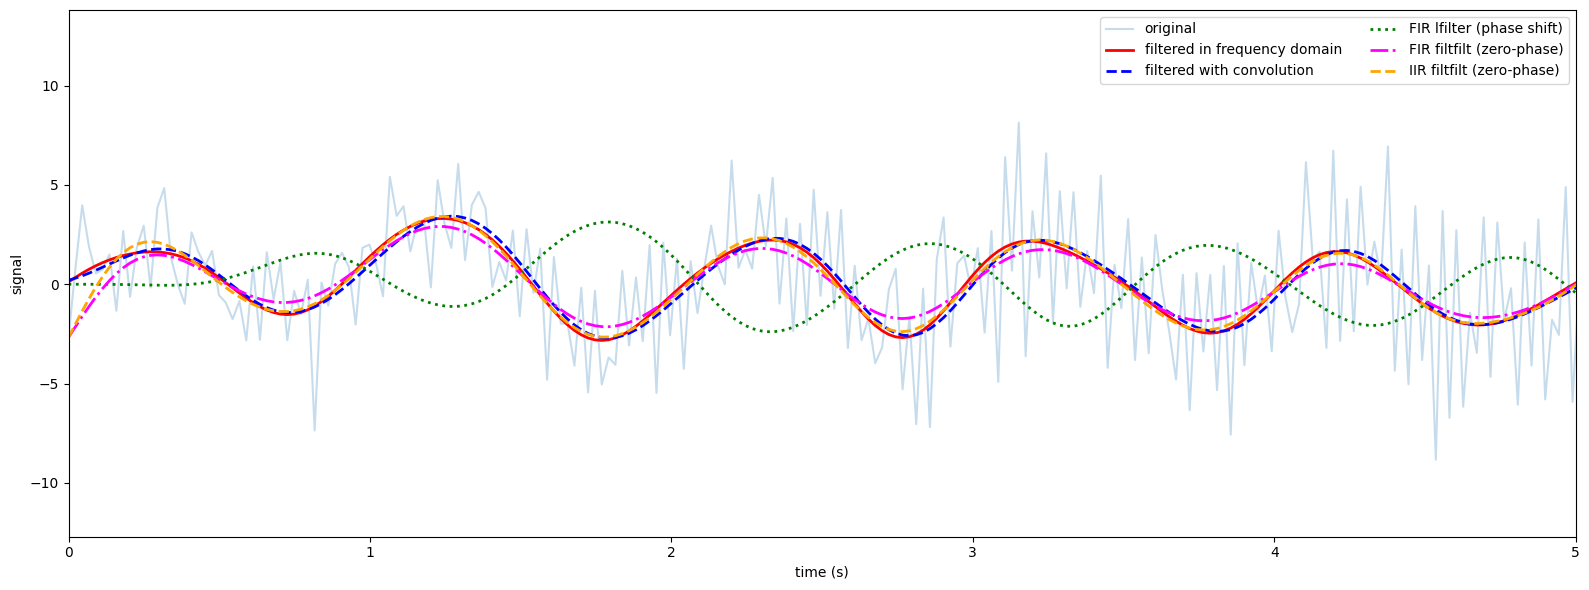

In [ ]:
# PORÓWNANIE WSZYSTKICH METOD

fig, ax = plt.subplots(figsize=(16, 6))

# Sygnał oryginalny
ax.plot(t, f_t, label="original", alpha=0.25)

ax.plot(t, f_t_filtered.real, "r", lw=2, label="filtered in frequency domain")

ax.plot(t, f_t_filtered_conv.real, "b--", lw=2, label="filtered with convolution")

ax.plot(
    t,
    f_t_fir_lfilter,
    color="green",
    linestyle=":",
    lw=2,
    label="FIR lfilter (phase shift)",
)

ax.plot(
    t,
    f_t_fir_filtfilt,
    color="magenta",
    linestyle="-.",
    lw=2,
    label="FIR filtfilt (zero-phase)",
)

ax.plot(
    t,
    f_t_iir_filtfilt,
    color="orange",
    linestyle="--",
    lw=2,
    label="IIR filtfilt (zero-phase)",
)

ax.set_xlim(0, 5)  # <- zachęcam do zmiany skali!
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend(loc="upper right", ncol=2)

plt.tight_layout()
plt.show()

# Ćwiczenia

Poniżej znajdują się przykłady wykorzystania filtrów FIR, IIR w plikach audio oraz na obrazkach. W kodzie znajdują się luki. Waszym zadaniem jest uzupełnić program tak, aby uzyskać efekt opiany w danej komórce.

## Zadanie 1

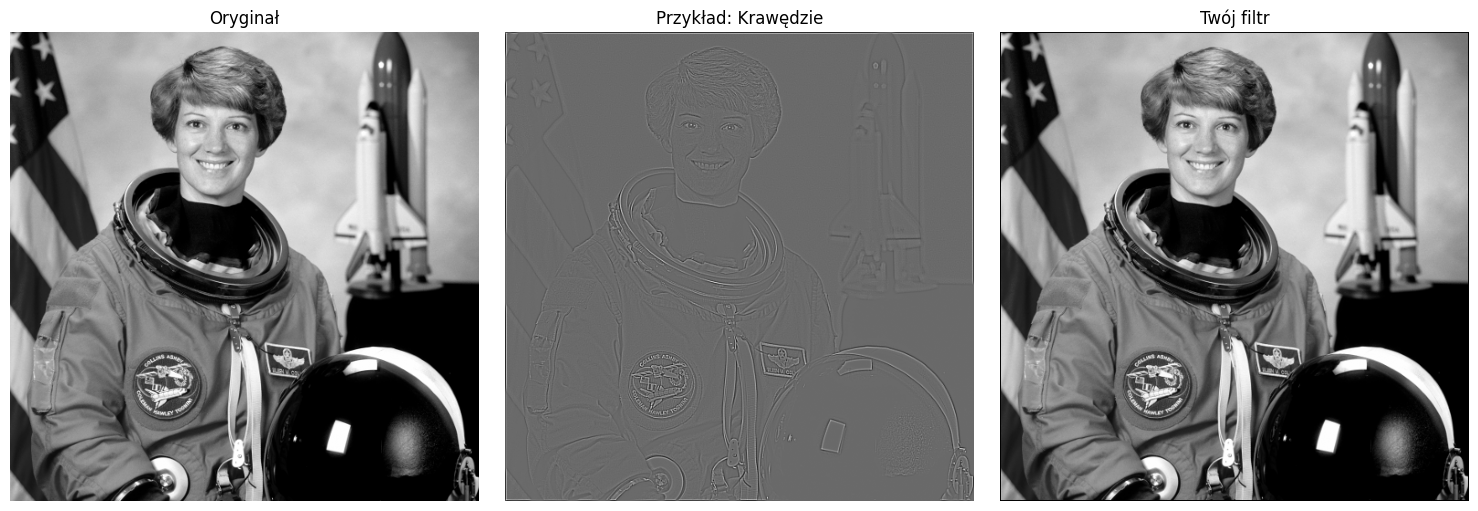

In [ ]:
from skimage import data, color
img = color.rgb2gray(data.astronaut())

# Przykład - filtr wykrywający krawędzie (Laplasjan)
kernel_edge = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])
img_edge = signal.convolve(img, kernel_edge)


# --- ZADANIE ---
# Zmodyfikuj poniższą macierz (tzw. kernel), aby uzyskać inny efekt filtracji.
# Spróbuj stworzyć:
# - filtr rozmywający (średnia z pikseli, suma wag = 1) 
# - wyostrzający obraz
# - filtr wykrywający linie poziome
# - filtr wykrywający linie pionowe
kernel_custom = np.array([
    [0, 0, 0],
    [0, 1, 0], 
    [0, 0, 0]
])

# Filtracja obrazu za pomocą Twojej macierzy
img_custom = signal.convolve(img, kernel_custom)

# Wyświetlenie wyników
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Oryginał')
axes[0].axis('off')

axes[1].imshow(img_edge, cmap='gray')
axes[1].set_title('Przykład: Krawędzie')
axes[1].axis('off')

axes[2].imshow(img_custom, cmap='gray')
axes[2].set_title('Twój filtr')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Zadanie 2

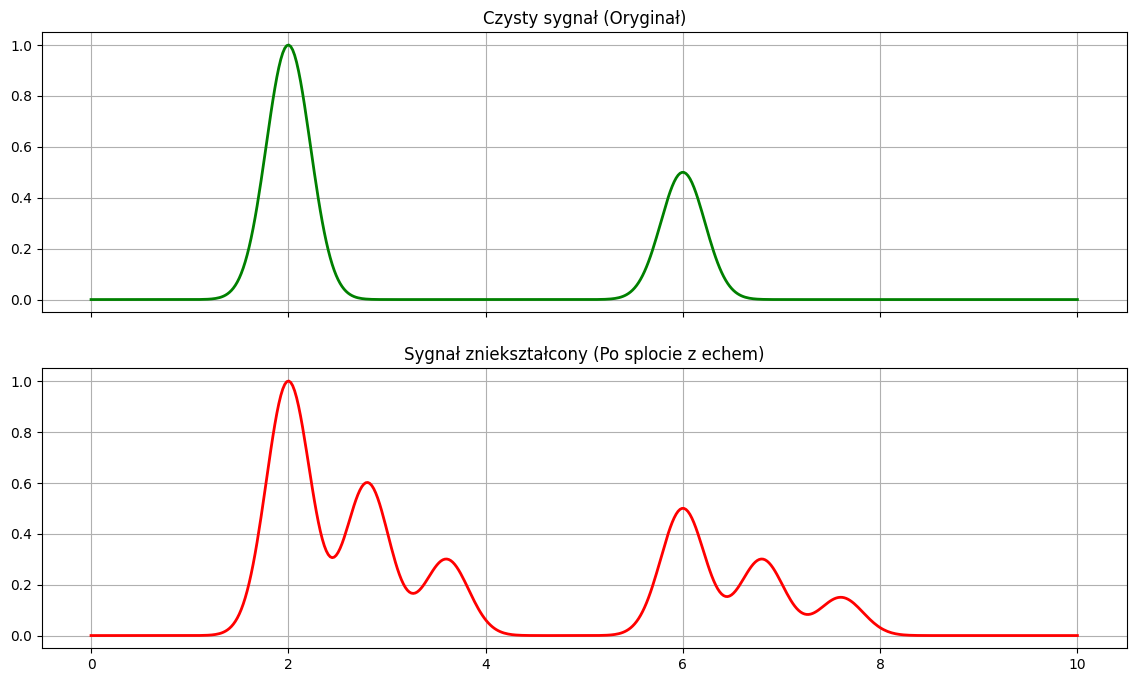

In [146]:
# Definicja czasu i czystego sygnału
N = 500
t = np.linspace(0, 10, N)
# Czysty sygnał - dwa wyraźne impulsy
x_clean = np.exp(-((t - 2)**2) / 0.1) + 0.5 * np.exp(-((t - 6)**2) / 0.1)

# Tworzenie jądra splotu (kernel) symulującego echo
kernel = np.zeros_like(t)
kernel[0] = 1.0       # Sygnał główny
kernel[40] = 0.6      # Pierwsze echo 
kernel[80] = 0.3      # Drugie echo

# Zniekształcenie sygnału (Splot / Convolution)
# Używamy 'full' i ucinamy do N, aby wektor miał tę samą długość co oś czasu
y_distorted = np.convolve(x_clean, kernel, mode='full')[:N]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(t, x_clean, color='green', lw=2)
axes[0].set_title("Czysty sygnał (Oryginał)")
axes[0].grid(True)

axes[1].plot(t, y_distorted, color='red', lw=2)
axes[1].set_title("Sygnał zniekształcony (Po splocie z echem)")
axes[1].grid(True)




ValueError: x and y must have same first dimension, but have shapes (500,) and (1,)

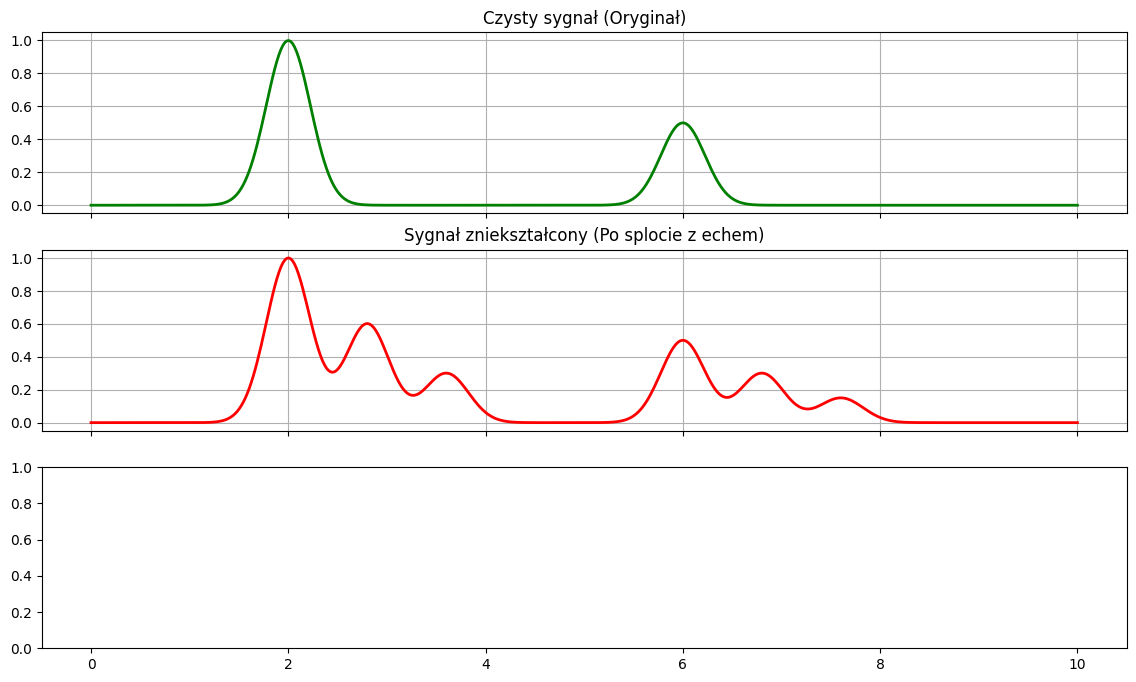

In [147]:
# --- ZADANIE: DEKONWOLUCJA ---
# Uzupełnij poniższy kod, aby odzyskać pierwotny sygnał. Przy fragmentach z lukami znajdują się podpowiedzi.

# Przejdź do dziedziny częstotliwości dla sygnału zniekształconego i jądra (użyj fft)
Y = ... # uzupełnij
H = ... # uzupełnij

# Zabezpieczenie przed dzieleniem przez zero w widmie
epsilon = 1e-10 

# Wykonaj dzielenie widm (odwrócenie splotu), pamiętaj o dodaniu epsilon do mianownika
X_recovered = ... # uzupełnij

# Wróć do dziedziny czasu (użyj ifft)
# Pamiętaj o wyciągnięciu tylko części rzeczywistej za pomocą .real
x_recovered = ... # uzupełnij
# ------------------------------------------


# Wizualizacja
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(t, x_clean, color='green', lw=2)
axes[0].set_title("Czysty sygnał (Oryginał)")
axes[0].grid(True)

axes[1].plot(t, y_distorted, color='red', lw=2)
axes[1].set_title("Sygnał zniekształcony (Po splocie z echem)")
axes[1].grid(True)

axes[2].plot(t, x_recovered, color='blue', linestyle='--', lw=2)
axes[2].set_title("Sygnał odzyskany (Dekonwolucja: IFFT( FFT(y) / FFT(kernel) ))")
axes[2].grid(True)
axes[2].set_xlabel("Czas [s]")

plt.tight_layout()
plt.show()